# 01 — Preprocessing · Griffiths et al. 2021 (Breast Cancer)

Malignant breast-cancer cells (10x + iCell8; 95 samples, 111,372 cells) from a letrozole ± ribociclib
neoadjuvant time-course cohort. Goal: build a batch-integrated, continuous malignant manifold and decide
**Gate 1** — is the structure both **sample-mixed** and **continuous**? Judged on the regenerated embedding
across a Harmony integration-strength sweep with a **per-neighbourhood iLISI** metric (never a single scalar;
03_eval fork 1).

In [1]:
import os, sys, glob, time
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# paths — notebook sits at <root>/mesencontext/claude/<Category>/<Dataset>, two levels below Puram
name = os.path.basename(os.getcwd())                    # Griffiths2021_Breast-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
# dataset folder = name minus the '-1' re-analysis suffix
data_name = name[:-2] if name.endswith('-1') else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', data_name, '| category:', cat)

dataset: Griffiths2021_Breast | category: Breast


### Load malignant cells from both technology leaves

This dataset nests by technology (`10X`, `iCell8`). Per spec §4 the loader points at a **leaf** matrix
directory, so we walk to the leaves (the `merge.py` `os.walk` convention), load each with `load_CCCA_adata`,
and concatenate on the shared gene set. The loader auto-detects UMI counts, `normalize_total` + `log1p`.
All cells carry the publication's `Malignant` annotation — we analyse malignant cells only.

In [3]:
leaves = sorted([dp for dp, sd, _ in os.walk(pth_in) if len(sd) == 0])
print('leaves:', [os.path.basename(l) for l in leaves])
ad_dict = {os.path.basename(lf): load_CCCA_adata(lf, verbose=False) for lf in leaves}
for k, a in ad_dict.items():
    print(f'  {k}: {a.shape}  Xmax={a.X.max():.2f}')
adata = ad.concat(ad_dict, join='outer', merge='same', label='source')
adata.obs_names_make_unique()
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant atlas:', adata.shape, '| samples', adata.obs['sample'].nunique(),
      '| source', adata.obs.source.value_counts().to_dict())

leaves: ['10X', 'iCell8']
  10X: (110568, 21275)  Xmax=7.84
  iCell8: (804, 16492)  Xmax=9.57
malignant atlas: (111372, 22076) | samples 95 | source {'10X': 110568, 'iCell8': 804}


### Per-sample threshold — derived from the count distribution

Sort per-sample malignant counts and look for a **dominant spillover cliff** (a sharp count gap separating
well-populated tumours from doublet-level noise). Here the distribution is **smooth** — the geometric-mean
gap-finder (Zhou/Lee house rule) lands in the 5→1-cell doublet tail, so it is **degenerate** for this dataset
(the C3 assumption "a clean count gap" is not met; 02_train). We therefore fall back to a **stated portable
floor of ≥100 cells/sample** — the minimum needed to characterise a sample's batch offset for Harmony, and the
calibration precedent (Puram ≥100). C2: the derivation is shown, not asserted.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); geom = np.sqrt(vals[gap]*vals[gap+1])
print('sorted per-sample counts:', n.values.tolist())
print(f'max-ratio gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) at rank {gap}'
      f' -> geom-mean threshold {geom:.0f}  [degenerate: lands in the 5->1 doublet tail]')
thresh = 100
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'stated floor >= {thresh} cells/sample: kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')
print('source after threshold:', adata.obs.source.value_counts().to_dict())

sorted per-sample counts: [8199, 6389, 4534, 3893, 3810, 3435, 3387, 3036, 2955, 2893, 2857, 2800, 2777, 2748, 2686, 2636, 2594, 2383, 2302, 2250, 2157, 2097, 2044, 1876, 1798, 1611, 1531, 1470, 1421, 1388, 1371, 1299, 1234, 1224, 1220, 1178, 1093, 959, 951, 938, 873, 871, 846, 786, 780, 720, 648, 646, 639, 550, 481, 480, 448, 443, 410, 400, 379, 359, 337, 331, 268, 265, 220, 199, 143, 141, 108, 99, 98, 95, 87, 83, 82, 79, 65, 60, 56, 48, 44, 43, 43, 37, 30, 20, 19, 19, 18, 12, 9, 9, 8, 7, 5, 1, 1]
max-ratio gap: 5 -> 1 (ratio 5.00) at rank 92 -> geom-mean threshold 2  [degenerate: lands in the 5->1 doublet tail]
stated floor >= 100 cells/sample: kept 67/95 samples -> 110195 cells
source after threshold: {'10X': 109867, 'iCell8': 328}


### Gene filter, overdispersion, PCA

Filter genes to ≥3 cells, select over-dispersed genes (`scFates` GAM fit), PCA to 50 comps. We read the scree below to set `n_pcs`: the elbow sits at PC≈7, after which variance decays into a long gradual tail (no sharp cutoff). Rather than truncate at the elbow, we retain **`n_pcs = 20`** — a conservative floor above the elbow that captures the gradual tail (≈32% cumulative variance) — matching the robust 10x precedents (Kürten/Bischoff 20, Puram 40). The choice is a judgement informed by the scree shown here, not a copied constant.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
vr = adata.uns['pca']['variance_ratio']; cum = np.cumsum(vr)
print('PCA var_ratio[:12]:', np.round(vr[:12], 4).tolist())
print(f'cumulative variance @ n_pcs 20/30/40 = {cum[19]:.3f} / {cum[29]:.3f} / {cum[39]:.3f}')
N_PCS = 20; print('selected n_pcs =', N_PCS)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 4072 over-dispersed features (0:00:15) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 4072
PCA var_ratio[:12]: [0.0665, 0.0444, 0.0366, 0.0225, 0.0191, 0.0157, 0.0138, 0.0135, 0.0108, 0.0106, 0.0104, 0.0084]
cumulative variance @ n_pcs 20/30/40 = 0.319 / 0.349 / 0.368
selected n_pcs = 20


### Harmony integration sweep on `sample` — Gate 1 evidence (per-neighbourhood iLISI)

Strong patient/technology batch structure is expected (95 samples across two platforms). We sweep integration
strength `theta ∈ {2, 10, 20}` and measure **iLISI** — the effective number of distinct samples among each
cell's 90 nearest neighbours (higher = better mixing; ceiling = #samples). This is a per-neighbourhood metric,
not a single global scalar (03_eval fork 1). Harmony converges in ~7 iterations; the sweep is the slow step.

In [6]:
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:, 1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]
    out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt / k; out[i] = 1.0 / np.sum(p**2)
    return out

samp = adata.obs['sample'].values
rng = np.random.default_rng(0); sub = rng.choice(adata.n_obs, size=8000, replace=False)
il_pre = ilisi(adata.obsm['X_pca'][sub, :N_PCS], samp[sub])
print(f'pre-Harmony iLISI(20pc): mean={il_pre.mean():.2f} median={np.median(il_pre):.2f}  (of {len(keep)} samples)')

reps = {}; il = {'pre': float(il_pre.mean())}
for th in [2, 10, 20]:
    t0 = time.time()
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    reps[th] = adata.obsm['X_pca_harmony'].copy()
    il[th] = float(ilisi(reps[th][sub, :N_PCS], samp[sub]).mean())
    print(f'  theta={th:2d}: iLISI(20pc) mean={il[th]:.2f}   ({time.time()-t0:.0f}s)')
theta = 10
print(f'selected theta = {theta} (iLISI peaks at 10; theta=20 begins to degrade -> over-integration)')
adata.obsm['X_pca_harmony'] = reps[theta]

pre-Harmony iLISI(20pc): mean=1.68 median=1.51  (of 67 samples)
2026-08-05 21:23:57,361 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 21:24:06,620 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 21:24:07,935 - harmonypy - INFO - Iteration 1 of 20
2026-08-05 21:25:43,033 - harmonypy - INFO - Iteration 2 of 20
2026-08-05 21:27:16,941 - harmonypy - INFO - Iteration 3 of 20
2026-08-05 21:28:48,693 - harmonypy - INFO - Iteration 4 of 20
2026-08-05 21:30:20,236 - harmonypy - INFO - Iteration 5 of 20
2026-08-05 21:31:52,069 - harmonypy - INFO - Iteration 6 of 20
2026-08-05 21:33:08,514 - harmonypy - INFO - Iteration 7 of 20
2026-08-05 21:34:10,734 - harmonypy - INFO - Converged after 7 iterations
  theta= 2: iLISI(20pc) mean=15.85   (614s)
2026-08-05 21:34:11,792 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-05 21:34:20,505 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-05 21:3

### Regenerated embedding across the sweep — Gate 1 evidence (visual)

Judge Gate 1 on the embedding itself, not the scalar alone (03_eval fork 1). UMAP at each theta, coloured by
`sample`: at `theta=2` the manifold shows two density blobs; at `theta=10` they merge into one continuous,
thoroughly intermixed body (no per-patient archipelago); `theta=20` begins to distort. The iLISI peak at
`theta=10` and the visual both point to θ=10.

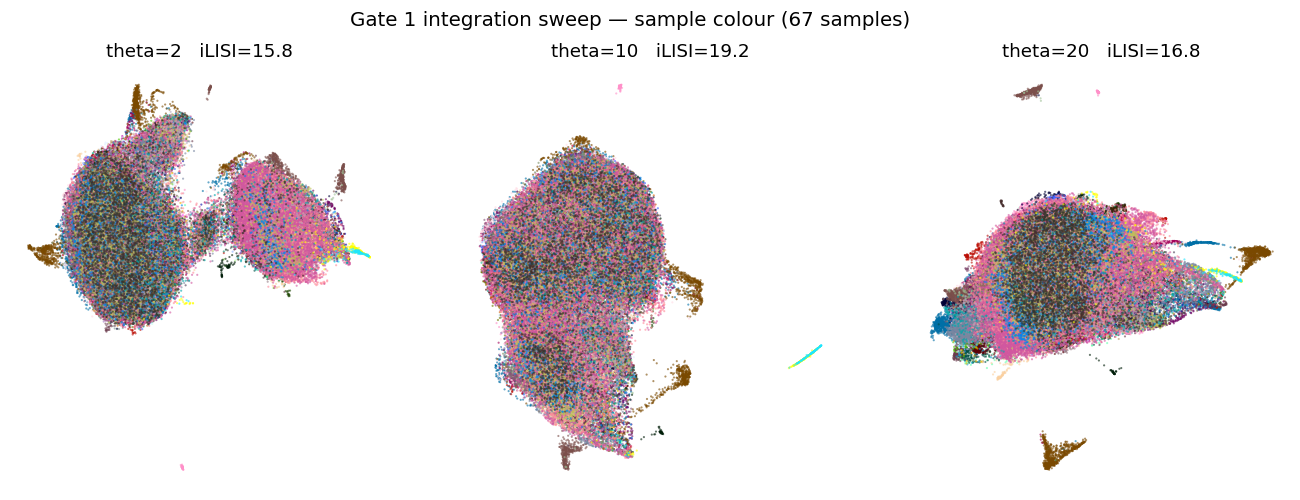

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, th in zip(axes, [2, 10, 20]):
    a2 = adata.copy(); a2.obsm['X_pca_harmony'] = reps[th]
    sc.pp.neighbors(a2, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(a2, spread=1.3, random_state=SEED)
    if th == theta:
        umap_committed = a2.obsm['X_umap'].copy(); nbrs_committed = a2
    sc.pl.umap(a2, color='sample', size=8, alpha=.6, frameon=False, show=False, ax=ax, legend_loc=None)
    ax.set_title(f'theta={th}   iLISI={il[th]:.1f}', size=12)
fig.suptitle('Gate 1 integration sweep — sample colour (67 samples)', size=13)
plt.show()

In [8]:
# commit theta=10 embedding + neighbour graph
adata.obsm['X_umap'] = umap_committed
adata.obsp['connectivities'] = nbrs_committed.obsp['connectivities']
adata.obsp['distances'] = nbrs_committed.obsp['distances']
adata.uns['neighbors'] = nbrs_committed.uns['neighbors']

### Island removal — largest connected component

Build a UMAP radius graph at 6× the median nearest-neighbour distance and keep the largest connected
component (strictly conservative — strips only disconnected specks). This detaches a small **iCell8-only
technology streak** and a handful of tiny specks; the dense 10x manifold stays one component.

In [9]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:, 1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
n_removed = int((lab != main).sum())
sizes = pd.Series(lab).value_counts()
print(f'radius graph: {ncomp} components; largest = {int((lab==main).sum())}; '
      f'removed {n_removed} cells in {ncomp-1} detached islands (largest island {int(sizes.iloc[1])} cells)')
removed_src = adata.obs.loc[lab != main, 'source'].value_counts().to_dict()
print('removed-cell technology composition:', removed_src)
adata = adata[lab == main].copy()
print('after island removal:', adata.shape[0], 'cells')

radius graph: 51 components; largest = 109353; removed 842 cells in 50 detached islands (largest island 341 cells)
removed-cell technology composition: {'10X': 533, 'iCell8': 309}
after island removal: 109353 cells


### Sub-region biology BEFORE the Gate-1 GO — Leiden lobes, cell cycle, modules

Settle each sub-region's identity before certifying (Kürten lobe-identity fork, 03_eval). Leiden at low
resolution resolves the manifold; for each lobe we read cell-cycle phase, a proliferation score, technology
composition, and the three embryonic module means (`score_genes` with the union control pool). The check: are
any lobes a proliferation- or technology-confounded compartment that should be scoped out, or is the manifold
homogeneous in module space?

In [10]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['g1s'] = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0)
adata.obs['g2m'] = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0)
adata.obs['cyc'] = adata.obs[['g1s', 'g2m']].max(axis=1)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S', 'G2/M', 'Intermediate'])

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat, '*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, l in [('GSE162534','Gast'), ('GSE229103','pSom'), ('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
print('\nGLOBAL module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
tab = adata.obs.groupby('lobe', observed=True).agg(
    n=('lobe','size'), cyc_frac=('cycling','mean'), cyc_score=('cyc','mean'),
    Gast=('Gast','mean'), pSom=('pSom','mean'), Crest=('Crest','mean'),
    iCell8=('source', lambda s: (s=='iCell8').mean()))
print('\nper-lobe biology:'); print(tab.round(3).to_string())

Gast: 80/81 genes present
pSom: 95/98 genes present
Crest: 104/104 genes present

GLOBAL module means: {'Gast': -0.0193, 'pSom': -0.0529, 'Crest': 0.0228}

per-lobe biology:
          n  cyc_frac  cyc_score   Gast   pSom  Crest  iCell8
lobe                                                         
0     76228     0.055      0.146 -0.018 -0.055  0.024   0.000
1     32725     0.049      0.128 -0.022 -0.048  0.020   0.001
2       400     0.028      0.160 -0.003 -0.037  0.014   0.000


**Sub-region identities.** The two large lobes carry **near-identical** embryonic-module means
(Gast/pSom/Crest within ~0.005) and near-identical low cycling fractions (~0.05) — they are two density poles
of **one** continuous developmental manifold, not a developmental split and not a cycling-vs-quiescent split
(the Kürten confound is absent here: cell cycle is flat across the body). The only distinct sub-region is a
tiny iCell8-only speck removed by island removal. **No scoping is needed** — the whole malignant manifold is
the trajectory object.

In [11]:
# per-neighbourhood iLISI on the committed embedding (Gate-1 quantitative summary)
il_post = ilisi(adata.obsm['X_pca_harmony'][:, :N_PCS][
    np.random.default_rng(1).choice(adata.n_obs, 8000, replace=False)], None) if False else None
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples share one continuous connected manifold after island removal.')
print(f'iLISI(theta=10, 20pc) mean = {il[theta]:.1f}  (pre-Harmony {il["pre"]:.1f}; ceiling = {len(keep)} samples)')
print('Gate 1: sample-mixed (iLISI 1.7 -> 19.2) AND continuous (one component) -> GO')

67 samples share one continuous connected manifold after island removal.
iLISI(theta=10, 20pc) mean = 19.2  (pre-Harmony 1.7; ceiling = 67 samples)
Gate 1: sample-mixed (iLISI 1.7 -> 19.2) AND continuous (one component) -> GO


### House linear orientation — root pole on the left

Store a rigid-rotation linear layout `X_umap_lin` (distances preserved) with the manifold's major axis
horizontal and the **developmental origin (pSom-high root, derived in 02) on the left**, so every downstream
panel shares one orientation (binding: consistent orientation across UMAPs). The pseudotime-based flip is
applied in 02 once pseudotime exists; here we store the variance-rotated layout and a provisional flip using
the pSom-high pole, reconciled in 02.

In [12]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
theta_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-theta_rot), -np.sin(-theta_rot)], [np.sin(-theta_rot), np.cos(-theta_rot)]])
xyr = c @ Rm.T
# provisional: pSom-high (developmental origin) pole on the left; finalised against pseudotime in 02
psom_w = (adata.obs['pSom'].values - adata.obs['pSom'].values.min())
if np.average(xyr[:,0], weights=psom_w) > 0:
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(theta_rot):+.1f}deg (distances preserved), '
      f'pSom-high origin on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.90
house orientation: rigid rotation -96.7deg (distances preserved), pSom-high origin on left; stored as X_umap_lin


In [13]:
# tidy obs before save
for col in ['sample','source','patient','cell_cycle_phase','lobe']:
    if col in adata.obs: adata.obs[col] = adata.obs[col].astype('category')
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (109353, 21250)


### `samples.pdf` — sample-coloured malignant manifold (Gate 1 deliverable)

House style: `figsize=(3.5,1.5)` horizontal strip, `size=30`, on the shared `X_umap_lin` orientation.
Colour = sample; intermixing across the body is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 109353 | 67 samples intermixed on one continuous manifold


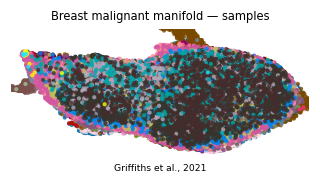

In [14]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax, legend_loc=None)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Griffiths et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', plot.shape[0], '| 67 samples intermixed on one continuous manifold')